# GDBN Data: Sanity Check

Before fitting anything, check that the dataset looks right. Each section ends with a **check** line that prints `OK` or `FLAG`.

1. Shape, dates, and missing values
2. Returns: sizes, extreme days, volatility
3. News sentiment: range and distribution
4. News attention: is there a trend over time?
5. Crisis checks: March 2020 and 2008
6. Correlations: do sectors move together?
7. News vs returns: same-day and next-day links
8. Summary of flags

**Kernel:** Python (thesis). Decisions about the model (e.g., whether to adjust attention) should be based on the **training period (2006–2020)** only.

In [ ]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller

pd.set_option("display.precision", 4)
DATA = Path("data")

wide = pd.read_csv(DATA / "gdbn_wide.csv", index_col="date", parse_dates=True).sort_index()
split = pd.read_csv(DATA / "splits" / "split_labels.csv", index_col="date", parse_dates=True)["split"]
universe = pd.read_csv(DATA / "universe.csv").drop_duplicates("ticker")

RET = [c for c in wide.columns if c.endswith("_ret")]
SENT = [c for c in wide.columns if c.endswith("_sent")]
ATTN = [c for c in wide.columns if c.endswith("_attn")]
STOCKS = [c[:-5] for c in SENT]
SECTOR = dict(zip(universe["ticker"], universe["sector"]))
train = wide[split == "train"]

flags = {}
def check(name, ok, detail=""):
    flags[name] = ok
    print(f"[{'OK' if ok else 'FLAG'}] {name}" + (f": {detail}" if detail else ""))

## 1. Shape, dates, and missing values

In [ ]:
print(f"{len(wide):,} trading days from {wide.index.min().date()} to {wide.index.max().date()}")
print(f"{len(RET)} returns + {len(SENT)} sentiment + {len(ATTN)} attention = {wide.shape[1]} variables")
print(split.value_counts().reindex(["train", "validation", "test"]))

check("95 variables", wide.shape[1] == 95, f"found {wide.shape[1]}")
check("No missing values", int(wide.isna().sum().sum()) == 0, f"{int(wide.isna().sum().sum())} missing cells")
check("No duplicate dates", not wide.index.duplicated().any())
gaps = wide.index.to_series().diff().dt.days
# Documented market closures (the exchange was closed, so no data is missing)
KNOWN_CLOSURES = {"2007-01-03": "President Ford's funeral (Jan 2) after New Year's Day",
                  "2012-10-31": "Hurricane Sandy (Oct 29-30)"}
long_gaps = gaps[gaps > 4]
for d, g in long_gaps.items():
    print(f"  {int(g)}-day gap ending {d.date()}: {KNOWN_CLOSURES.get(str(d.date()), 'UNKNOWN: check this')}")
check("No unexplained gaps longer than 4 calendar days",
      all(str(d.date()) in KNOWN_CLOSURES for d in long_gaps.index), f"{len(long_gaps)} long gaps, all documented closures")

4,713 trading days from 2006-04-11 to 2024-12-31
35 returns + 30 sentiment + 30 attention = 95 variables
split
train         3708
validation     503
test           502
Name: count, dtype: int64
[OK] 95 variables: found 95
[OK] No missing values: 0 missing cells
[OK] No duplicate dates
  5-day gap ending 2007-01-03: President Ford's funeral (Jan 2) after New Year's Day
  5-day gap ending 2012-10-31: Hurricane Sandy (Oct 29-30)
[OK] No unexplained gaps longer than 4 calendar days: 2 long gaps, all documented closures


## 2. Returns

Daily returns are usually small (around ±1–2%), with occasional large moves. A single-day move above ±30% for a large company would be suspicious (possible data error).

In [ ]:
ret_stats = pd.DataFrame({
    "mean (%)": wide[RET].mean() * 100,
    "std (%)": wide[RET].std() * 100,
    "annual vol (%)": wide[RET].std() * np.sqrt(252) * 100,
    "min (%)": wide[RET].min() * 100,
    "max (%)": wide[RET].max() * 100,
}).rename(index=lambda c: c[:-4]).sort_values("annual vol (%)")
ret_stats

,mean (%),std (%),annual vol (%),min (%),max (%)
TLT,0.0173,0.9520,15.1123,-6.6683,7.5196
JNJ,0.0369,1.0880,17.2709,-10.0379,12.2292
GLD,0.0360,1.1155,17.7074,-8.7808,11.2905
PG,0.0407,1.1505,18.2639,-8.7373,12.0090
PEP,0.0384,1.1537,18.3144,-11.9314,12.9366
KO,0.0422,1.1643,18.4826,-9.6725,13.8795
DBC,0.0085,1.2188,19.3476,-7.9444,6.8744
SPY,0.0471,1.2277,19.4886,-10.9424,14.5198
WMT,0.0543,1.2834,20.3730,-11.3758,11.7085
COST,0.0780,1.4187,22.5211,-12.4513,10.7514


In [ ]:
# Largest single-day moves (look up whether each matches a real event)
moves = wide[RET].stack().rename("ret").reset_index()
moves.columns = ["date", "series", "ret"]
moves["abs"] = moves["ret"].abs()
print(moves.nlargest(10, "abs")[["date", "series", "ret"]].assign(ret=lambda d: (d["ret"] * 100).round(1)).to_string(index=False))

# Every move above ±40% should match a real event (otherwise it may be a data error)
KNOWN_EVENTS = {("2008-10-13", "MS_ret"): "Mitsubishi UFJ investment closes + global bank rescue plans",
                ("2008-11-24", "C_ret"): "US government rescue of Citigroup",
                ("2020-03-09", "OXY_ret"): "Saudi-Russia oil price war + COVID crash"}
huge = moves[moves["abs"] > 0.40]
for _, r in huge.iterrows():
    print(f"  {r['date'].date()} {r['series'][:-4]:>5} {r['ret']:+.1%}: {KNOWN_EVENTS.get((str(r['date'].date()), r['series']), 'UNKNOWN: check this')}")
check("Every move above ±40% is a documented event",
      all((str(r["date"].date()), r["series"]) in KNOWN_EVENTS for _, r in huge.iterrows()), f"{len(huge)} moves above 40%")
check("Average daily returns are small (|mean| < 0.5%)", (wide[RET].mean().abs() < 0.005).all())

      date  series   ret
2008-10-13  MS_ret  87.0
2008-11-24   C_ret  57.8
2020-03-09 OXY_ret -50.5
2009-02-27   C_ret -39.0
2009-03-10   C_ret  38.1
2009-04-09 BAC_ret  35.3
2008-10-13 UNH_ret  34.8
2020-06-05 OXY_ret  33.7
2008-11-24  MS_ret  33.1
2008-07-16 WFC_ret  32.8
  2008-10-13    MS +87.0%: Mitsubishi UFJ investment closes + global bank rescue plans
  2008-11-24     C +57.8%: US government rescue of Citigroup
  2020-03-09   OXY -50.5%: Saudi-Russia oil price war + COVID crash
[OK] Every move above ±40% is a documented event: 3 moves above 40%
[OK] Average daily returns are small (|mean| < 0.5%)


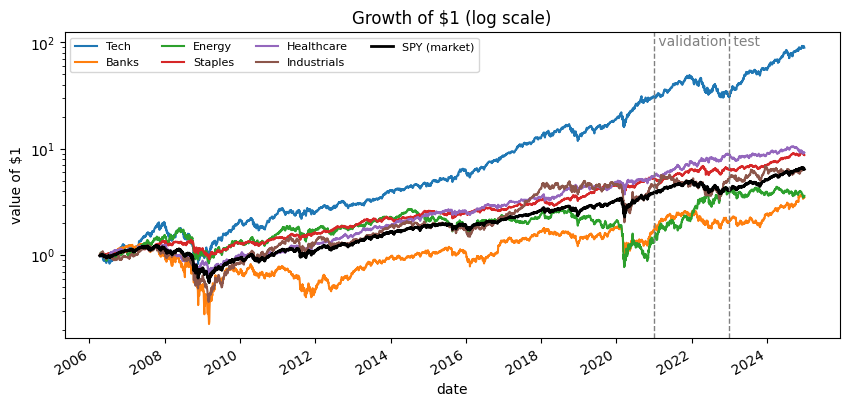

In [ ]:
# Growth of $1 by sector (equal-weighted within sector)
fig, ax = plt.subplots(figsize=(10, 4.5))
for sector in ["Tech", "Banks", "Energy", "Staples", "Healthcare", "Industrials"]:
    cols = [f"{t}_ret" for t in STOCKS if SECTOR.get(t) == sector]
    (1 + wide[cols].mean(axis=1)).cumprod().plot(ax=ax, label=sector)
(1 + wide["SPY_ret"]).cumprod().plot(ax=ax, label="SPY (market)", color="black", lw=2)
for d, name in [("2021-01-01", "validation"), ("2023-01-01", "test")]:
    ax.axvline(pd.Timestamp(d), color="gray", ls="--", lw=1)
    ax.text(pd.Timestamp(d), ax.get_ylim()[1] * 0.95, f" {name}", color="gray")
ax.set_yscale("log"); ax.set_title("Growth of $1 (log scale)"); ax.set_ylabel("value of $1"); ax.legend(ncol=4, fontsize=8)
plt.show()

## 3. News sentiment

Sentiment should lie between −1 and +1, with 0 on days with no news.

Range: -0.990 to 0.950
Share of stock-days with sentiment exactly 0: 24.7%
Among nonzero days: mean +0.101, median +0.125, share positive 65.8%
[OK] Sentiment within [-1, 1]


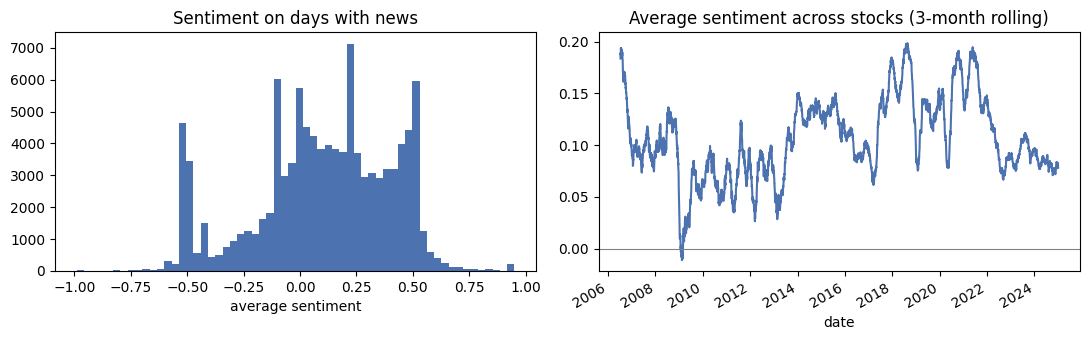

In [ ]:
s = wide[SENT]
print(f"Range: {s.min().min():.3f} to {s.max().max():.3f}")
print(f"Share of stock-days with sentiment exactly 0: {(s == 0).mean().mean():.1%}")
nonzero = s.values[s.values != 0]
print(f"Among nonzero days: mean {nonzero.mean():+.3f}, median {np.median(nonzero):+.3f}, share positive {(nonzero > 0).mean():.1%}")

check("Sentiment within [-1, 1]", s.min().min() >= -1 and s.max().max() <= 1)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(nonzero, bins=60, color="#4c72b0"); ax[0].set_title("Sentiment on days with news"); ax[0].set_xlabel("average sentiment")
s.replace(0, np.nan).mean(axis=1).rolling(63).mean().plot(ax=ax[1], color="#4c72b0")
ax[1].axhline(0, color="gray", lw=0.8); ax[1].set_title("Average sentiment across stocks (3-month rolling)")
plt.tight_layout(); plt.show()

**What to look for:** news sentiment is usually **skewed positive** (companies issue lots of positive press releases). That is fine, but it means a sentiment of 0.1 is not "good news," just average. Standardizing each variable (using training statistics) handles this in the model.

## 4. News attention: is there a trend?

If the number of stories rises over the years, the model could mistake "more news overall" for a signal. Check the yearly average and test for a trend **in the training period**.

      avg attention  avg stories/day  days with news (%)
year                                                    
2006           2.08            15.17               89.54
2007           2.22            16.96               93.48
2008           2.25            20.92               95.24
2009           2.15            17.50               91.59
2010           2.11            16.55               91.71
2011           2.12            15.69               92.08
2012           2.17            17.65               92.55
2013           1.94            13.99               87.49
2014           1.89            15.15               84.44
2015           1.80            15.48               80.93
2016           1.79            12.85               83.35
2017           1.78            12.48               81.22
2018           1.76            15.22               75.98
2019           1.77            14.03               76.23
2020           1.83            16.21               76.88
2021           1.95            

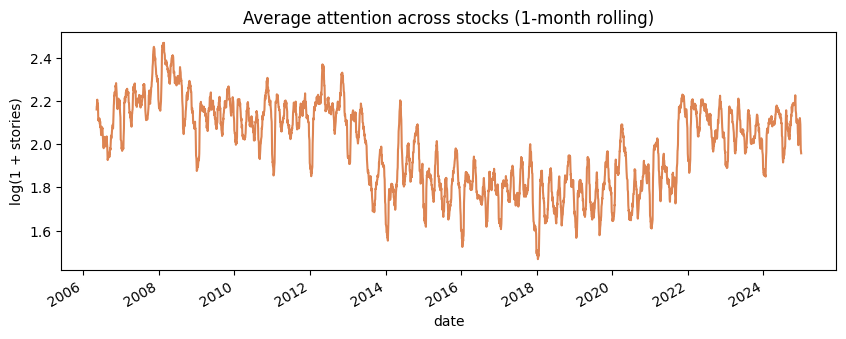

[OK] Attention stationary in training period (ADF p < 0.05): ADF p = 0.00159
[OK] Attention level stable 2006 -> 2020 (change < 20%): 2.08 -> 1.83


In [ ]:
a = wide[ATTN]
yearly = pd.DataFrame({
    "avg attention": a.mean(axis=1).groupby(a.index.year).mean(),
    "avg stories/day": np.expm1(a).mean(axis=1).groupby(a.index.year).mean(),
    "days with news (%)": (a > 0).mean(axis=1).groupby(a.index.year).mean() * 100,
}).round(2)
yearly.index.name = "year"
print(yearly.to_string())

fig, ax = plt.subplots(figsize=(10, 3.5))
a.mean(axis=1).rolling(21).mean().plot(ax=ax, color="#dd8452")
ax.set_title("Average attention across stocks (1-month rolling)"); ax.set_ylabel("log(1 + stories)")
plt.show()

# Trend test on the training period: ADF test (small p-value = no persistent trend / stationary)
train_attn = train[ATTN].mean(axis=1)
p = adfuller(train_attn, regression="c")[1]
first, last = yearly["avg attention"].iloc[0], yearly.loc[2020, "avg attention"]
check("Attention stationary in training period (ADF p < 0.05)", p < 0.05, f"ADF p = {p:.3g}")
check("Attention level stable 2006 -> 2020 (change < 20%)", abs(last / first - 1) < 0.20, f"{first:.2f} -> {last:.2f}")

**If attention is FLAGGED:** a simple fix is to measure attention **relative to the stock's recent normal**, e.g., today's attention minus its average over the past 60 days ("abnormal attention"). That keeps the news spikes but removes slow trends in overall news volume.

## 5. Crisis checks: March 2020 and 2008

During the COVID crash, the market fell sharply, so news attention should spike and sentiment should drop. If the news data tracks real events, it should show up here.

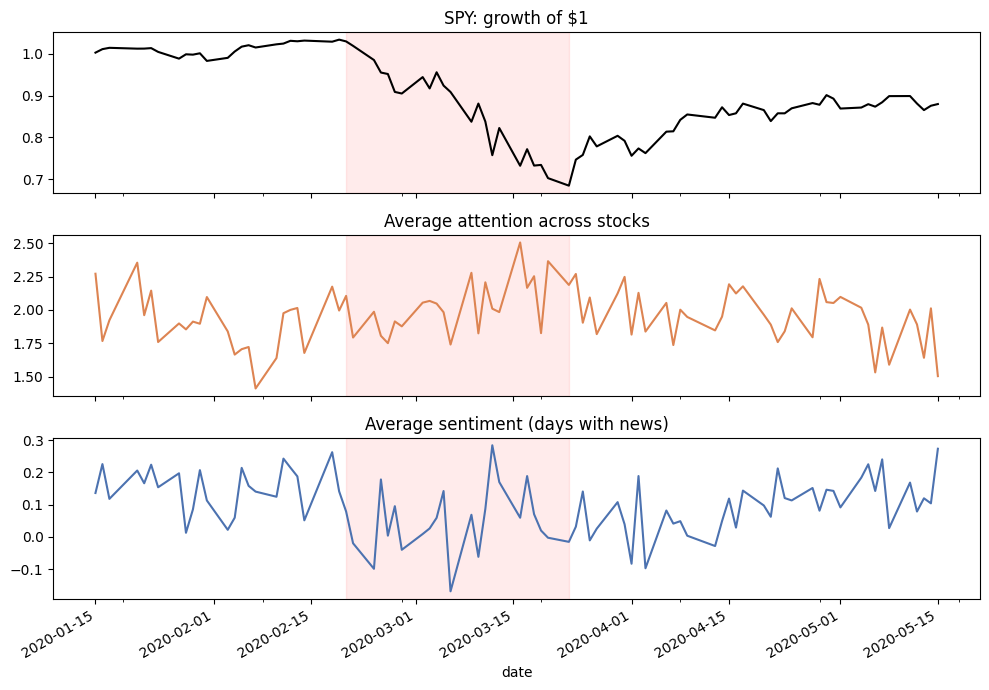

Attention: 2019 avg 1.77 vs crash 2.03
Sentiment: 2019 avg +0.130 vs crash +0.050
[OK] Attention higher during the crash
[OK] Sentiment lower during the crash


In [ ]:
window = wide.loc["2020-01-15":"2020-05-15"]
fig, ax = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
(1 + window["SPY_ret"]).cumprod().plot(ax=ax[0], color="black"); ax[0].set_title("SPY: growth of $1")
window[ATTN].mean(axis=1).plot(ax=ax[1], color="#dd8452"); ax[1].set_title("Average attention across stocks")
window[SENT].replace(0, np.nan).mean(axis=1).plot(ax=ax[2], color="#4c72b0"); ax[2].set_title("Average sentiment (days with news)")
for axis in ax:
    axis.axvspan(pd.Timestamp("2020-02-20"), pd.Timestamp("2020-03-23"), color="red", alpha=0.08)
plt.tight_layout(); plt.show()

calm = wide.loc["2019-01-01":"2019-12-31"]
crash = wide.loc["2020-02-20":"2020-03-23"]
att_calm, att_crash = calm[ATTN].mean().mean(), crash[ATTN].mean().mean()
sent_calm = calm[SENT].replace(0, np.nan).mean().mean()
sent_crash = crash[SENT].replace(0, np.nan).mean().mean()
print(f"Attention: 2019 avg {att_calm:.2f} vs crash {att_crash:.2f}")
print(f"Sentiment: 2019 avg {sent_calm:+.3f} vs crash {sent_crash:+.3f}")
check("Attention higher during the crash", att_crash > att_calm)
check("Sentiment lower during the crash", sent_crash < sent_calm)

**Same check for the 2008 financial crisis** (Lehman Brothers failed on Sep 15, 2008): compare Sep 15 to Nov 20, 2008 with calm 2006–2007.

In [ ]:
calm08 = wide.loc[:"2007-06-30"]
crash08 = wide.loc["2008-09-15":"2008-11-20"]
att_calm, att_crash = calm08[ATTN].mean().mean(), crash08[ATTN].mean().mean()
sent_calm = calm08[SENT].replace(0, np.nan).mean().mean()
sent_crash = crash08[SENT].replace(0, np.nan).mean().mean()
print(f"SPY during the window: {(1 + crash08['SPY_ret']).prod() - 1:+.1%}")
print(f"Attention: calm {att_calm:.2f} vs crisis {att_crash:.2f}")
print(f"Sentiment: calm {sent_calm:+.3f} vs crisis {sent_crash:+.3f}")
check("2008: attention higher during the crisis", att_crash > att_calm)
check("2008: sentiment lower during the crisis", sent_crash < sent_calm)

SPY during the window: -39.8%
Attention: calm 2.13 vs crisis 2.23
Sentiment: calm +0.114 vs crisis +0.106
[OK] 2008: attention higher during the crisis
[OK] 2008: sentiment lower during the crisis


## 6. Correlations: do sectors move together?

Stocks in the same sector should be more correlated with each other than with other sectors. Computed on the **training period** only.

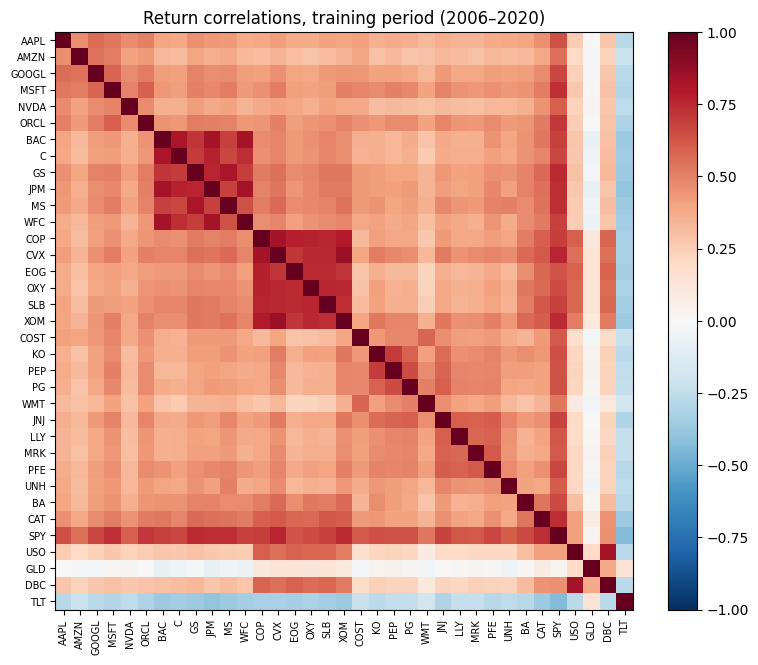

Average correlation within sectors:  0.63
Average correlation between sectors: 0.42
Oil (USO) vs energy stocks: 0.57   vs other stocks: 0.24
[OK] Within-sector correlation > between-sector
[OK] Oil correlates more with energy stocks than others


In [ ]:
order = [t for sec in ["Tech", "Banks", "Energy", "Staples", "Healthcare", "Industrials"] for t in STOCKS if SECTOR.get(t) == sec]
order += ["SPY", "USO", "GLD", "DBC", "TLT"]
corr = train[[f"{t}_ret" for t in order]].corr()
corr.index = corr.columns = order

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(order)), order, rotation=90, fontsize=7); ax.set_yticks(range(len(order)), order, fontsize=7)
fig.colorbar(im, fraction=0.046); ax.set_title("Return correlations, training period (2006–2020)")
plt.show()

within, between = [], []
stock_order = [t for t in order if t in STOCKS]
for i, a1 in enumerate(stock_order):
    for b1 in stock_order[i + 1:]:
        (within if SECTOR[a1] == SECTOR[b1] else between).append(corr.loc[a1, b1])
print(f"Average correlation within sectors:  {np.mean(within):.2f}")
print(f"Average correlation between sectors: {np.mean(between):.2f}")
energy = [t for t in STOCKS if SECTOR.get(t) == "Energy"]
print(f"Oil (USO) vs energy stocks: {corr.loc['USO', energy].mean():.2f}   vs other stocks: {corr.loc['USO', [t for t in STOCKS if t not in energy]].mean():.2f}")
check("Within-sector correlation > between-sector", np.mean(within) > np.mean(between))
check("Oil correlates more with energy stocks than others", corr.loc["USO", energy].mean() > corr.loc["USO", [t for t in STOCKS if t not in energy]].mean())

## 7. News vs returns

- **Same day:** a stock's sentiment and its **stock-specific return** (its return minus the market's, SPY) should be positively related (good company news, the stock beats the market). This confirms the news is matched to the right company and day.
- **Next day:** sentiment today vs the stock-specific return tomorrow is the signal the GDBN could use. Expect it to be **small** (markets react fast).

**Why stock-specific returns:** company news explains the company's own move, not the whole market's. In 2007–2009, company sentiment was actually **negatively** related to the market's move (on crash days, the company-specific stories that passed the relevance filter were more positive than usual), which hides the company-level link if raw returns are used.

Training period only; days with news only.

In [ ]:
rows = []
for t in STOCKS:
    df = train[[f"{t}_sent", f"{t}_ret", f"{t}_attn", "SPY_ret"]].copy()
    df["specific"] = df[f"{t}_ret"] - df["SPY_ret"]          # stock-specific return
    df["next_specific"] = df["specific"].shift(-1)
    df = df[df[f"{t}_attn"] > 0].dropna()
    rows.append({"stock": t,
                 "same-day corr": df[f"{t}_sent"].corr(df["specific"]),
                 "next-day corr": df[f"{t}_sent"].corr(df["next_specific"]),
                 "same-day corr (raw return)": df[f"{t}_sent"].corr(df[f"{t}_ret"])})
links = pd.DataFrame(rows).set_index("stock").sort_values("same-day corr")
print(links.round(3).to_string())
print(f"\nAverage same-day correlation: {links['same-day corr'].mean():+.3f}")
print(f"Average next-day correlation: {links['next-day corr'].mean():+.3f}")
check("Same-day sentiment-return link positive on average", links["same-day corr"].mean() > 0)
check("Same-day link stronger than next-day link", links["same-day corr"].mean() > links["next-day corr"].abs().mean())

       same-day corr  next-day corr  same-day corr (raw return)
stock                                                          
WFC           -0.039          0.051                      -0.093
MS            -0.002         -0.010                      -0.014
BAC            0.003          0.009                      -0.023
JPM            0.017          0.012                      -0.001
C              0.023         -0.004                       0.010
CVX            0.042          0.027                      -0.046
OXY            0.048          0.024                      -0.010
GS             0.049         -0.026                       0.037
XOM            0.053         -0.009                      -0.048
AMZN           0.057         -0.005                       0.063
MSFT           0.058          0.023                       0.037
ORCL           0.062         -0.002                      -0.003
GOOGL          0.071         -0.002                       0.080
COST           0.078         -0.011     

**Year by year (all years, for information):** the average correlation of sentiment on day $t$ with the return on day $t-1$ (yesterday), $t$ (same day), and $t+1$ (tomorrow), plus the split into the market part and the stock-specific part.

In [ ]:
by_year = {}
for y in sorted(set(wide.index.year)):
    sub = wide.loc[str(y)]
    vals = {"ret t-1": [], "ret t": [], "ret t+1": [], "market t": [], "specific t": []}
    for t in STOCKS:
        df = pd.DataFrame({"s": wide[f"{t}_sent"], "a": wide[f"{t}_attn"], "r": wide[f"{t}_ret"], "m": wide["SPY_ret"]})
        df["r_prev"], df["r_next"] = df["r"].shift(1), df["r"].shift(-1)
        df = df.loc[str(y)]
        df = df[df["a"] > 0].dropna()
        if len(df) < 30:
            continue
        vals["ret t-1"].append(df["s"].corr(df["r_prev"])); vals["ret t"].append(df["s"].corr(df["r"]))
        vals["ret t+1"].append(df["s"].corr(df["r_next"])); vals["market t"].append(df["s"].corr(df["m"]))
        vals["specific t"].append(df["s"].corr(df["r"] - df["m"]))
    by_year[y] = {k: np.mean(v) for k, v in vals.items()}
by_year = pd.DataFrame(by_year).T
by_year.index.name = "year"
by_year.round(3)

,ret t-1,ret t,ret t+1,market t,specific t
year,,,,,
2006,0.058,0.002,0.017,-0.095,0.067
2007,0.037,0.015,0.038,-0.152,0.160
2008,-0.002,-0.154,0.044,-0.221,0.034
2009,0.035,-0.027,0.030,-0.166,0.118
2010,0.026,0.120,0.039,0.017,0.144
2011,0.035,0.007,-0.015,-0.072,0.096
2012,0.030,0.084,0.027,0.009,0.096
2013,0.062,0.061,0.033,-0.030,0.098
2014,0.044,0.057,0.012,-0.008,0.077


**What to look for:**
- **specific t** should be positive in every year (news aligned with the right company and day).
- **market t** negative in 2007–2009: a crisis-era effect, not a data error.
- **ret t-1 jumps** from about 0.05 to about 0.3 from 2021–2022 on: sentiment starts to strongly **echo yesterday's price move** (likely more automated "stock moved" stories in the newer RavenPack data; news coverage also jumps to 100% of days). This is **not look-ahead** (it looks backward), but it means sentiment behaves differently in validation and test than in training. A possible fix is to exclude RavenPack's price-movement story types in `pull_data.py`.

**Reading this:** a clearly positive same-day correlation means the news data is aligned correctly. A tiny next-day correlation is normal: it is the hard part of prediction, and why the GDBN needs to be compared with simple baselines.

## 8. Summary

In [ ]:
summary = pd.Series(flags).map({True: "OK", False: "FLAG"}).rename("result")
print(summary.to_string())
n_flag = int((~pd.Series(flags)).sum())
print(f"\n{len(flags) - n_flag} OK, {n_flag} FLAG")

95 variables                                              OK
No missing values                                         OK
No duplicate dates                                        OK
No unexplained gaps longer than 4 calendar days           OK
Every move above ±40% is a documented event               OK
Average daily returns are small (|mean| < 0.5%)           OK
Sentiment within [-1, 1]                                  OK
Attention stationary in training period (ADF p < 0.05)    OK
Attention level stable 2006 -> 2020 (change < 20%)        OK
Attention higher during the crash                         OK
Sentiment lower during the crash                          OK
2008: attention higher during the crisis                  OK
2008: sentiment lower during the crisis                   OK
Within-sector correlation > between-sector                OK
Oil correlates more with energy stocks than others        OK
Same-day sentiment-return link positive on average        OK
Same-day link stronger t